# Rollout diagnostics (ICLR 2027 rebuttal, 2b)

This notebook reads the files that `scripts/evaluation/rollout_diagnostics.py` writes and turns them into the tables and plots of D1 to D6. The definitions are in `context_flux_no.metrics`, and the reductions to summary numbers are in `context_flux_no.evaluation.summarize_rollouts`.

The first section runs the script on a few trajectories as a trial. The full runs are started from the command line, one test set per run.

In [1]:
from pathlib import Path

import colorcet as cc
import h5py
import matplotlib.pyplot as plt
import numpy as np
from context_flux_no.evaluation import (
    summarize_conservation_drift,
    summarize_rollouts,
)
from context_flux_no.metrics import RolloutReferences


plt.style.use("context_flux_no.plotting.styles.dash_gridded")

output_dir = Path("../../data/analysis/rollout_diagnostics")

# Group names of the result files -> names and colors of the paper.
LABELS = {"HyperFluxFNOLocal": "HFluxNO", "DPOT": "DPOT", "DISCO": "DISCO"}
COLORS = {
    "HyperFluxFNOLocal": cc.cm.glasbey_bw(41),
    "DPOT": cc.cm.glasbey_bw(85),
    "DISCO": cc.cm.glasbey_bw(68),
}
HORIZON = 80
REPORT_STEPS = (20, 40, 80)
# Whether the summaries of D2 to D5 leave out the trajectories whose reference is a
# constant state (see `summarize_rollouts`). The per-step curves of D1 and the result
# files hold every trajectory either way.
EXCLUDE_CONSTANT_REFERENCES = True

## Trial run

`--limit 16` evaluates the first 16 trajectories and writes `cubic_1d_limit16.hdf5`, so a trial never overwrites a full result. Any preset or argument of the script can be used here.

In [ ]:
%run ../../scripts/evaluation/rollout_diagnostics.py --preset cubic_1d --limit 16 \
    --data-root ../../data --checkpoint-root ../../checkpoints --output-dir {output_dir}

## Loading

`load_results` returns the reference quantities, the per-model arrays with the seeds as their first axis, and the attributes of the file.

In [2]:
def load_results(
    name: str,
) -> tuple[RolloutReferences, dict[str, dict[str, np.ndarray]], dict]:
    with h5py.File(output_dir / f"{name}.hdf5", "r") as f:
        references = RolloutReferences(**{k: v[()] for k, v in f["references"].items()})
        models = {
            group: {k: v[()] for k, v in f[group].items()}
            for group in f
            if group in LABELS
        }
        attributes = dict(f.attrs)
    return references, models, attributes


def summarize(name: str) -> dict[str, dict]:
    """The summary of D2 to D5 for every model of one test set, pooled over seeds."""
    references, models, _ = load_results(name)
    return {
        group: summarize_rollouts(
            arrays["l2"],
            arrays["nonfinite"],
            arrays["area_fraction"],
            arrays["total_variation"],
            references,
            exclude_constant_references=EXCLUDE_CONSTANT_REFERENCES,
            minima=arrays.get("minima"),
            horizon=HORIZON,
            report_steps=REPORT_STEPS,
        )
        for group, arrays in models.items()
    }


# The test sets whose result file exists.
names = sorted(p.stem for p in output_dir.glob("*.hdf5") if "_limit" not in p.stem)
names

['burgers_1d',
 'burgers_1d_shock',
 'cubic_1d',
 'cubic_1d_shock',
 'cubicflux_2d',
 'cubicflux_2d_shock',
 'euler_2d',
 'euler_2d_shock',
 'shallow_water_1d',
 'shallow_water_1d_shock']

## Valid horizon (D2) and failure statistics (D3)

The valid horizon is the first step at which a rollout is no better than the identity baseline. A rollout that stays below the identity baseline for all 80 steps counts as 80, and the column "never" gives the fraction of such rollouts. The column "step 1" gives the fraction that is no better than the identity baseline at the first step.

In [3]:
for name in names:
    print(name)
    for group, s in summarize(name).items():
        q25, q50, q75 = s["valid_horizon_quartiles"]
        row = (
            f"  {LABELS[group]:8s} horizon {q50:3.0f} [{q25:3.0f}, {q75:3.0f}]"
            f"  never {s['fraction_never_crossed']:6.1%}"
            f"  step 1 {s['fraction_crossed_at_step_1']:6.1%}"
        )
        for key, label in [
            ("fraction_nonfinite", "non-finite"),
            ("fraction_diverged", "diverged"),
            ("fraction_nonpositive", "non-positive"),
        ]:
            if s[key] is not None:
                row += f"  {label} " + "/".join(
                    f"{s[key][n]:.1%}" for n in REPORT_STEPS
                )
        print(row)

burgers_1d
  DISCO    horizon  41 [ 28,  60]  never  11.7%  step 1   0.0%  non-finite 0.0%/0.0%/0.0%  diverged 7.6%/63.5%/99.3%
  DPOT     horizon  80 [ 80,  80]  never  98.7%  step 1   0.0%  non-finite 0.0%/0.0%/0.0%  diverged 0.1%/2.7%/34.8%
  HFluxNO  horizon  80 [ 80,  80]  never  99.3%  step 1   0.0%  non-finite 0.0%/0.0%/0.0%  diverged 0.0%/0.2%/2.7%
burgers_1d_shock
  DISCO    horizon  35 [ 24,  57]  never  11.5%  step 1   5.5%  non-finite 0.0%/0.0%/0.0%  diverged 4.8%/63.8%/98.5%
  DPOT     horizon  80 [ 80,  80]  never  77.9%  step 1   1.5%  non-finite 0.0%/0.0%/0.0%  diverged 3.7%/12.2%/42.6%
  HFluxNO  horizon  80 [ 80,  80]  never  94.7%  step 1   1.5%  non-finite 0.0%/0.0%/0.0%  diverged 0.7%/2.6%/11.9%
cubic_1d
  DISCO    horizon  80 [ 80,  80]  never  83.0%  step 1   1.3%  non-finite 0.0%/0.0%/0.0%  diverged 3.0%/15.7%/55.4%
  DPOT     horizon  80 [ 53,  80]  never  69.4%  step 1   0.7%  non-finite 0.0%/0.0%/0.0%  diverged 4.2%/31.9%/78.2%
  HFluxNO  horizon  80 [ 80,  8

In [10]:
for name in ["cubic_1d_shock", "burgers_1d_shock"]:
    print(name, {LABELS[g]: s["num_constant_references"] for g, s in summarize(name).items()})

cubic_1d_shock {'DISCO': 2013, 'DPOT': 2013, 'HFluxNO': 2013}
burgers_1d_shock {'DISCO': 2013, 'DPOT': 2013, 'HFluxNO': 2013}


## Per-step error with the two baselines (D1)

The curves are medians over seeds and trajectories, as in Fig. 3(a). The dashed line is the identity-baseline error and the dotted line is the error of the spatial-mean baseline. Non-finite errors are left out of the median, and D3 reports their fraction.

/home/jhko725/projects/CONTEXT_FLUX_NO/.venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a, func=_nanmedian, keepdims=keepdims,


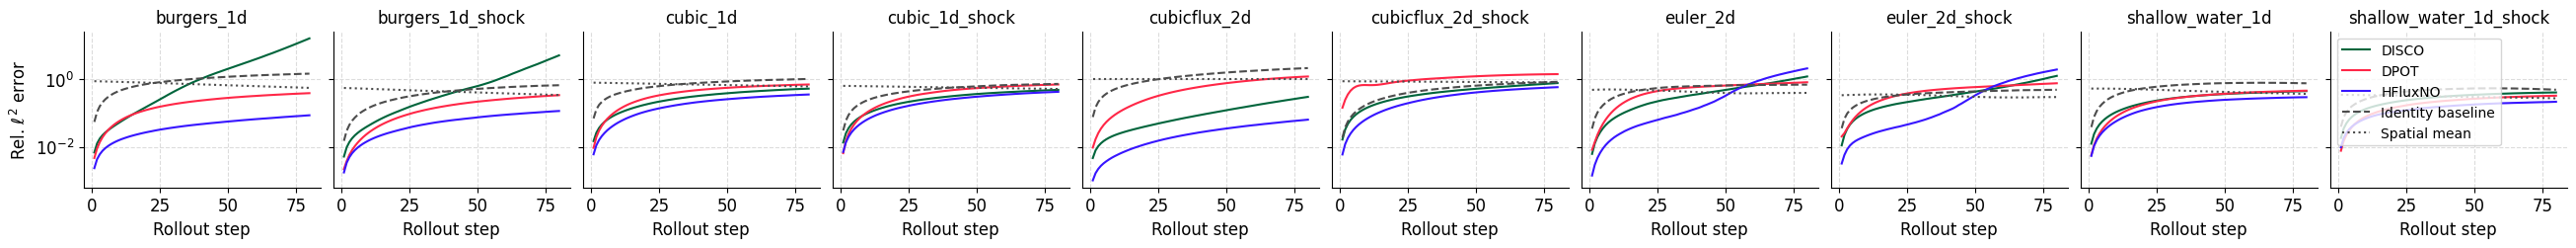

In [4]:
def nanmedian_over_rollouts(values: np.ndarray) -> np.ndarray:
    """Median over all axes but the last, ignoring non-finite entries."""
    flat = values.reshape(-1, values.shape[-1])
    return np.nanmedian(np.where(np.isfinite(flat), flat, np.nan), axis=0)


fig, axes = plt.subplots(
    1,
    len(names),
    figsize=(2.6 * len(names), 2.4),
    sharey=True,
    constrained_layout=True,
    squeeze=False,
)
for ax, name in zip(axes[0], names):
    references, models, attributes = load_results(name)
    steps = np.arange(1, HORIZON + 1)
    for group, arrays in models.items():
        ax.plot(
            steps,
            nanmedian_over_rollouts(arrays["l2"])[:HORIZON],
            color=COLORS[group],
            label=LABELS[group],
        )
    ax.plot(
        steps,
        nanmedian_over_rollouts(references.l2_identity)[:HORIZON],
        color="0.3",
        ls="--",
        label="Identity baseline",
    )
    ax.plot(
        steps,
        nanmedian_over_rollouts(references.l2_spatial_mean)[:HORIZON],
        color="0.3",
        ls=":",
        label="Spatial mean",
    )
    ax.set_yscale("log")
    ax.set_title(name, fontsize="medium")
    ax.set_xlabel("Rollout step")
axes[0, 0].set_ylabel("Rel. $\\ell^2$ error")
axes[0, -1].legend(fontsize="small")

## Error area fraction (D4) and total-variation ratio (D5)

Both are medians over the rollouts that are finite at the step. The area fraction uses the threshold 0.1 of the reference range. A total-variation ratio above 1 marks ringing and a ratio below 1 marks smearing.

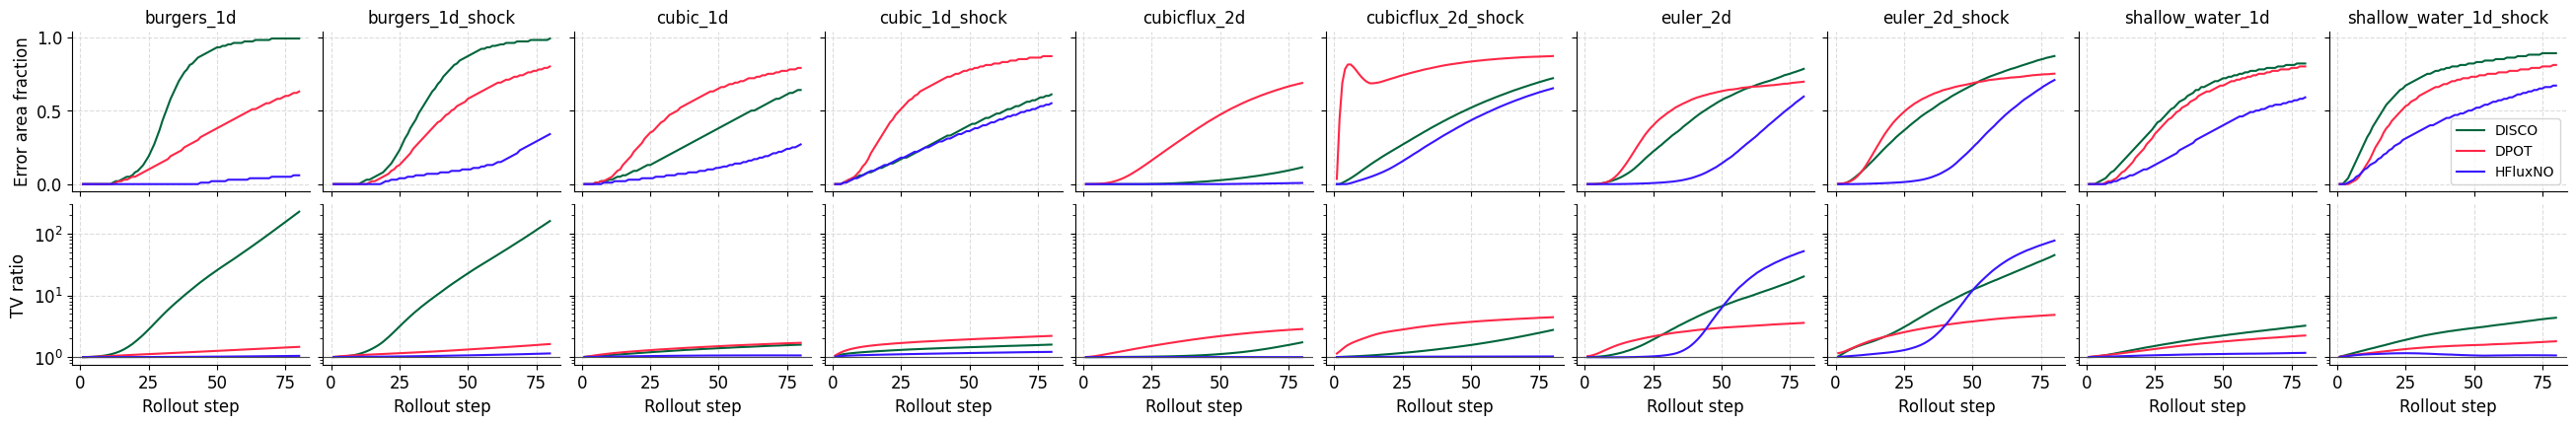

In [5]:
fig, axes = plt.subplots(
    2,
    len(names),
    figsize=(2.6 * len(names), 4.2),
    sharex=True,
    sharey="row",
    constrained_layout=True,
    squeeze=False,
)
for column, name in enumerate(names):
    references, models, attributes = load_results(name)
    threshold_index = list(attributes["area_thresholds"]).index(0.1)
    steps = np.arange(1, HORIZON + 1)
    for group, arrays in models.items():
        finite = ~arrays["nonfinite"]
        area = np.where(finite, arrays["area_fraction"][..., threshold_index], np.nan)
        with np.errstate(invalid="ignore", divide="ignore"):
            ratio = np.where(
                finite, arrays["total_variation"] / references.total_variation, np.nan
            )
        axes[0, column].plot(
            steps,
            nanmedian_over_rollouts(area)[:HORIZON],
            color=COLORS[group],
            label=LABELS[group],
        )
        axes[1, column].plot(
            steps, nanmedian_over_rollouts(ratio)[:HORIZON], color=COLORS[group]
        )
    axes[1, column].axhline(1.0, color="0.3", lw=0.8)
    axes[1, column].set_yscale("log")
    axes[0, column].set_title(name, fontsize="medium")
    axes[1, column].set_xlabel("Rollout step")
axes[0, 0].set_ylabel("Error area fraction")
axes[1, 0].set_ylabel("TV ratio")
axes[0, -1].legend(fontsize="small")

## Error spectrum (D6)

The spectrum of the error in the first conserved variable, relative to the total power of the reference and with wavenumbers in cycles per domain, for the test sets with two spatial dimensions. The vertical lines mark the patch wavenumber of DPOT and the grid-scale limit: 16 and 64 for 2D Euler, 10 and 25 for 2D cubic. A test set that is not listed in `WAVENUMBER_MARKS` is drawn without them.

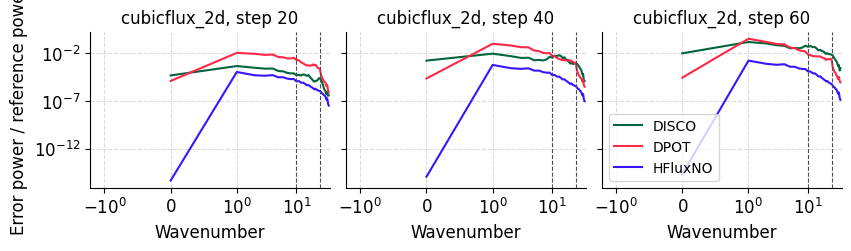

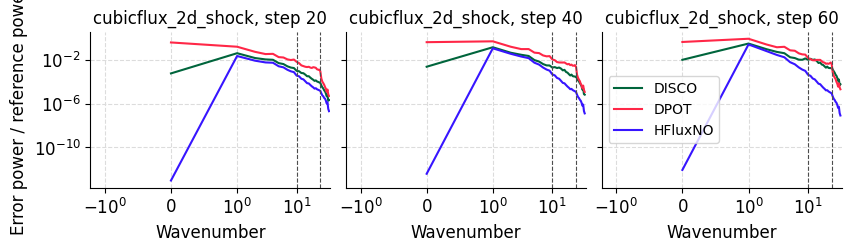

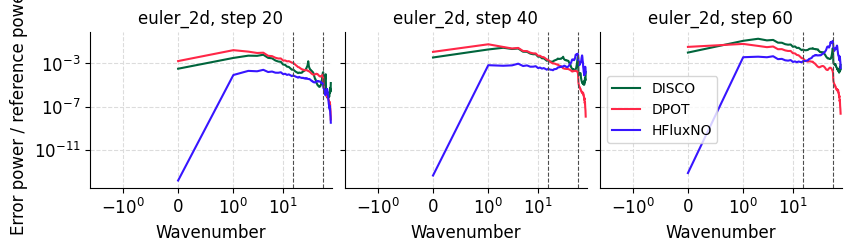

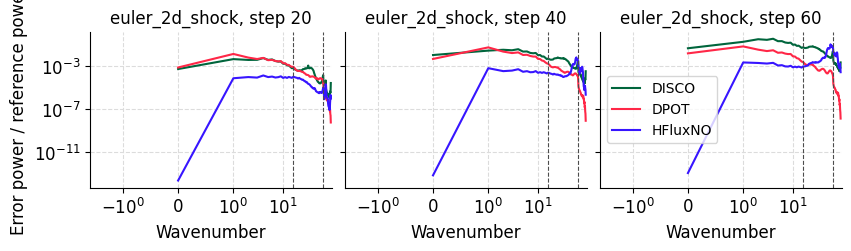

In [6]:
WAVENUMBER_MARKS = {
    "euler_2d": (16, 64),
    "euler_2d_shock": (16, 64),
    "cubicflux_2d": (10, 25),
    "cubicflux_2d_shock": (10, 25),
}

for name in names:
    references, models, attributes = load_results(name)
    spectrum_steps = attributes["spectrum_steps"]
    if len(spectrum_steps) == 0:
        continue
    fig, axes = plt.subplots(
        1,
        len(spectrum_steps),
        figsize=(2.8 * len(spectrum_steps), 2.4),
        sharey=True,
        constrained_layout=True,
    )
    for i, (ax, step) in enumerate(zip(axes, spectrum_steps)):
        for group, arrays in models.items():
            # Mean over seeds of the mean over trajectories.
            spectrum = np.nanmean(arrays["error_spectrum"][:, i], axis=0)
            ax.plot(
                np.arange(len(spectrum)),
                spectrum,
                color=COLORS[group],
                label=LABELS[group],
            )
        for mark in WAVENUMBER_MARKS.get(name, ()):
            ax.axvline(mark, color="0.3", lw=0.8, ls="--")
        ax.set_xscale("symlog", linthresh=1)
        ax.set_yscale("log")
        ax.set_title(f"{name}, step {step}", fontsize="medium")
        ax.set_xlabel("Wavenumber")
    axes[0].set_ylabel("Error power / reference power")
    axes[-1].legend(fontsize="small")

## Conservation drift

The drift of a channel at step n is |I(n) − I(0)| / ∫|u(0)|, where I is the integral of the channel over the domain and u(0) is the last context state.

Both the table and the curves follow the protocol of the per-step error of the long rollouts: the three seeds and all test trajectories are pooled, and the entries are the median with the 25th and 75th percentiles over those rollouts. The drift of a diverging rollout grows without bound, so a mean over rollouts would be set by a few of them, and a band of one standard deviation would reach below zero.

The table gives three numbers per rollout: the mean of the drift over the steps, the drift at the last step, and the largest drift. A rollout that turns non-finite within the horizon is left out of the table, and the fraction that remains is printed when it is below 1. The curves leave a rollout out from the step at which it turns non-finite. The dashed line is the median drift of the test data itself.

In [ ]:
KINDS = ("mean", "final", "worst")

for name in names:
    references, models, _ = load_results(name)
    summaries = {"Reference": summarize_conservation_drift(references.conservation_drift, horizon=HORIZON)}
    for group, arrays in models.items():
        # The seed axis is pooled with the trajectories.
        summaries[LABELS[group]] = summarize_conservation_drift(arrays["conservation_drift"], horizon=HORIZON)
    print(f"{name}: median [25%, 75%] over rollouts")
    for channel in range(references.conservation_drift.shape[-1]):
        print(f"  channel {channel:<4d}" + "".join(f"{kind:>34s}" for kind in KINDS))
        for label, summary in summaries.items():
            cells = ""
            for kind in KINDS:
                low, median, high = summary[kind][:, channel]
                cells += f"{median:>12.2e} [{low:.2e}, {high:.2e}]"
            finite = summary["fraction_finite"][channel]
            note = "" if finite == 1.0 else f"   finite: {finite:.1%}"
            print(f"  {label:12s}{cells}{note}")

In [ ]:
def median_and_quartiles(values: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Median, 25th and 75th percentile per step over all leading axes pooled.

    Non-finite entries are left out, as for the per-step error of the long rollouts.
    """
    pooled = values.reshape(-1, values.shape[-1])
    pooled = np.where(np.isfinite(pooled), pooled, np.nan)
    low, median, high = np.nanpercentile(pooled, [25, 50, 75], axis=0)
    return median, low, high


# Two single-precision sums can agree to the last bit, which gives a drift of exactly
# zero. The log axis cannot show zero, so the curves are drawn no lower than this.
DRIFT_FLOOR = 1e-10


for name in names:
    references, models, _ = load_results(name)
    num_channels = references.conservation_drift.shape[-1]
    steps = np.arange(1, HORIZON + 1)
    fig, axes = plt.subplots(
        1, num_channels, figsize=(3.0 * num_channels, 2.4), sharey=True, constrained_layout=True, squeeze=False
    )
    for channel, ax in enumerate(axes[0]):
        for group, arrays in models.items():
            # (seed, trajectory, step) pooled to (rollout, step)
            median, low, high = median_and_quartiles(arrays["conservation_drift"][..., :HORIZON, channel])
            median, low, high = (np.maximum(curve, DRIFT_FLOOR) for curve in (median, low, high))
            ax.plot(steps, median, color=COLORS[group], label=LABELS[group])
            ax.fill_between(steps, low, high, color=COLORS[group], alpha=0.15, lw=0)
        reference, _, _ = median_and_quartiles(references.conservation_drift[:, :HORIZON, channel])
        ax.plot(steps, np.maximum(reference, DRIFT_FLOOR), color="0.3", ls="--", label="Reference")
        ax.set_yscale("log")
        ax.set_title(f"{name}, channel {channel}", fontsize="medium")
        ax.set_xlabel("Rollout step")
    axes[0, 0].set_ylabel("Conservation drift")
    axes[0, -1].legend(fontsize="small")

## Positivity

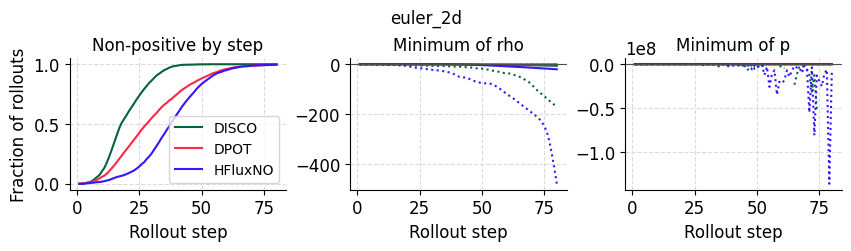

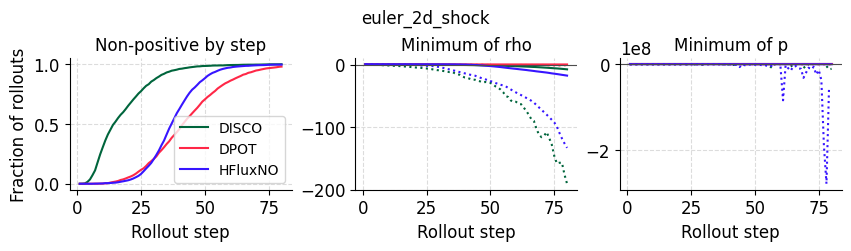

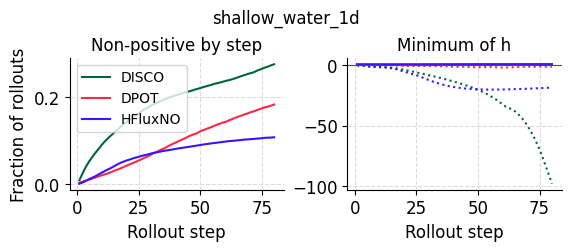

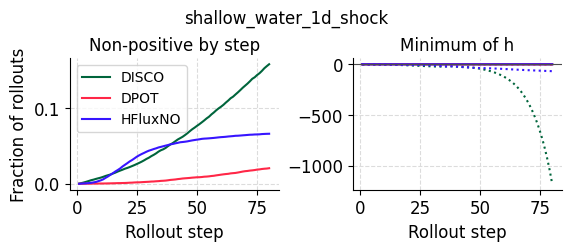

In [9]:
for name in names:
    references, models, attributes = load_results(name)
    minima_names = list(attributes["minima_names"])
    if not minima_names:
        continue
    steps = np.arange(1, HORIZON + 1)
    fig, axes = plt.subplots(
        1,
        len(minima_names) + 1,
        figsize=(2.8 * (len(minima_names) + 1), 2.4),
        constrained_layout=True,
    )
    for group, arrays in models.items():
        minima = arrays["minima"][
            ..., :HORIZON, :
        ]  # (seed, trajectory, step, quantity)
        # A rollout counts from the first step at which any quantity is at or below zero.
        with np.errstate(invalid="ignore"):
            violated = np.maximum.accumulate(np.any(minima <= 0.0, axis=-1), axis=-1)
        axes[0].plot(
            steps, violated.mean(axis=(0, 1)), color=COLORS[group], label=LABELS[group]
        )
        for ax, quantity in zip(axes[1:], range(len(minima_names))):
            ax.plot(
                steps,
                nanmedian_over_rollouts(minima[..., quantity]),
                color=COLORS[group],
            )
            ax.plot(
                steps,
                np.nanmin(minima[..., quantity], axis=(0, 1)),
                color=COLORS[group],
                ls=":",
            )
    axes[0].set_ylabel("Fraction of rollouts")
    axes[0].set_title("Non-positive by step", fontsize="medium")
    fig.suptitle(name, fontsize="medium")
    axes[0].legend(fontsize="small")
    for ax, quantity in zip(axes[1:], minima_names):
        ax.axhline(0.0, color="0.3", lw=0.8)
        ax.set_title(f"Minimum of {quantity}", fontsize="medium")
    for ax in axes:
        ax.set_xlabel("Rollout step")